# A/B тест новой формы оплаты ЖКХ

**Задача:** проверить, увеличила ли новая форма оплаты (с автозаполнением реквизитов) долю успешных оплат ЖКХ, и решить, запускать ли ее на всех пользователей.

- **Воронка:** 1. Открыл форму → 2. Ввел реквизиты → 3. Подтвердил платеж → 4. Успешная оплата.
- **Ключевая метрика:** конверсия из шага 1 в шаг 4.
- **Группы:** A — старая форма, B — новая форма.
- **Период теста:** 1–30 апреля 2024.
- **Данные сплитовались по клиентам**.
- **Гипотеза:** H0 — конверсия в группах не различается, H1 — различается.
- **Единица анализа — пользователь:** у одного клиента может быть несколько платежей, поэтому считаем, что пользователь "сконвертировался", если у него есть хотя бы одна успешная оплата.

**План:** 
1. Загрузка данных
2. Разведочный анализ (EDA)
3. Очистка и подготовка
4. Оценка корректности эксперимента¶
5. Статистические тесты
6. Визуализации
7. Выводы, ограничения и рекомендации

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

DATA_PATH = "C:\projects\df.xlsx" 

# 1. Загрузка данных

In [2]:
users_raw = pd.read_excel(DATA_PATH, sheet_name="Пользователи")
pay_raw   = pd.read_excel(DATA_PATH, sheet_name="Платежи")
print("Пользователи:", users_raw.shape, "| Платежи:", pay_raw.shape)

Пользователи: (1504, 5) | Платежи: (2661, 7)


# 2. Разведочный анализ данных (EDA)

### 2.1 Структура, пропуски, дубликаты

In [3]:
# Выведем информацию по таблице "Пользователи"

print(f"=== {"Пользователи"}: {users_raw.shape[0]} строк, {users_raw.shape[1]} колонок")
display(users_raw.head(3))
print("Пропуски:", users_raw.isna().sum()[lambda s: s > 0].to_dict())
print("Полные дубли строк:", users_raw.duplicated().sum())
print("Дубли user_id:", users_raw.user_id.duplicated().sum())

=== Пользователи: 1504 строк, 5 колонок


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android


Пропуски: {'group': 1, 'city': 1}
Полные дубли строк: 0
Дубли user_id: 0


In [4]:
# Выведем информацию по таблице "Платежи"

print(f"=== {"Платежи"}: {pay_raw.shape[0]} строк, {pay_raw.shape[1]} колонок")
display(pay_raw.head(3))
print("Пропуски:", pay_raw.isna().sum()[lambda s: s > 0].to_dict())
print("Полные дубли строк:", pay_raw.duplicated().sum())
print("Дубли payment_id:", pay_raw.payment_id.duplicated().sum())

=== Платежи: 2661 строк, 7 колонок


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT


Пропуски: {'user_id': 1, 'step2_entered': 405, 'step3_confirmed': 942, 'step4_success': 1139}
Полные дубли строк: 0
Дубли payment_id: 0


### 2.2 Значения признаков и период теста

In [5]:
# Значения категориальных столбцов и период
print("group:", users_raw.group.value_counts(dropna=False).to_dict())
print("city:", users_raw.city.value_counts(dropna=False).to_dict())
print("device_type:", users_raw.device_type.value_counts(dropna=False).to_dict())
print("Период:", pay_raw.step1_opened.min(), "–", pay_raw.step1_opened.max())

group: {'A': 752, 'B': 751, nan: 1}
city: {'Москва': 595, 'Регион': 514, 'СПб': 394, nan: 1}
device_type: {'android': 777, 'ios': 727}
Период: 2024-04-01 00:19:00 – 2024-04-30 23:17:00


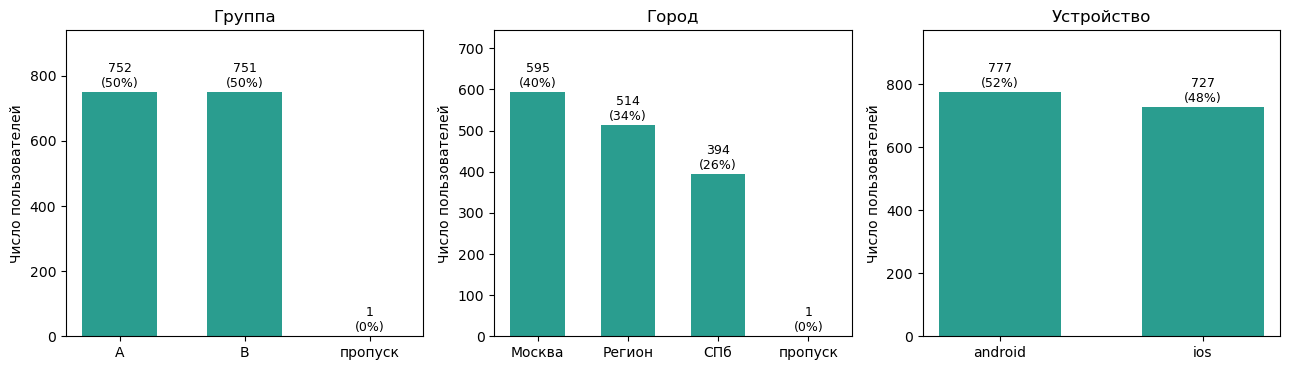

In [6]:
# Визуализация распределения в категориальных столбцах
cat_cols = {"group": "Группа", "city": "Город", "device_type": "Устройство"}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (col, title) in zip(axes, cat_cols.items()):
    counts = users_raw[col].fillna("пропуск").value_counts()
    colors = ["crimson" if k == "пропуск" else "#2a9d8f" for k in counts.index]
    ax.bar(counts.index, counts.values, color=colors, width=0.6)
    for i, v in enumerate(counts.values):
        ax.text(i, v + counts.max() * 0.02, f"{v}\n({v / len(users_raw) * 100:.0f}%)", ha="center", fontsize=9)
    ax.set_title(title); ax.set_ylabel("Число пользователей"); ax.set_ylim(0, counts.max() * 1.25)
    ax.grid(False)
plt.tight_layout()
plt.show()

In [7]:
# Описательная статистика поля age
display(users_raw.age.describe().round(1))

count    1504.0
mean       32.7
std         8.4
min        -5.0
25%        27.0
50%        33.0
75%        38.0
max       150.0
Name: age, dtype: float64

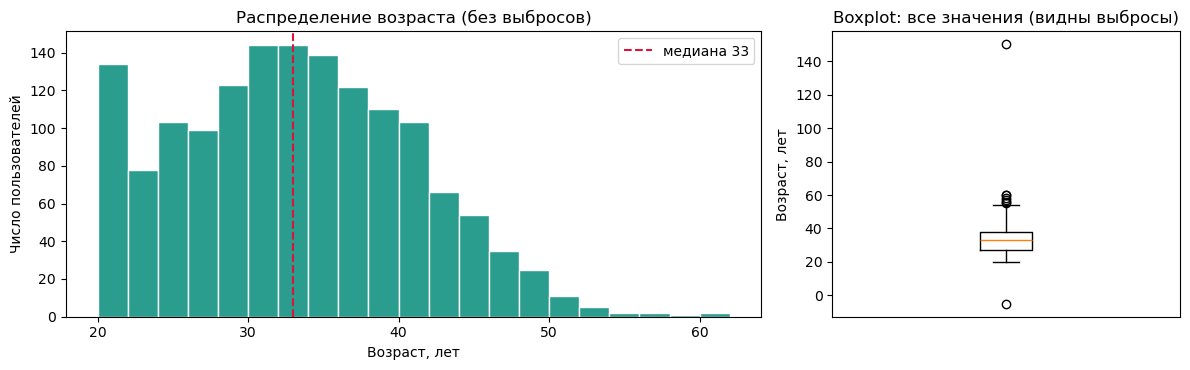

In [8]:
# Визуализация распределения данных в поле age
age_ok = users_raw.age[users_raw.age.between(14, 100)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]})

# Гистограмма без выбросов
axes[0].hist(age_ok, bins=range(int(age_ok.min()), int(age_ok.max()) + 3, 2), color="#2a9d8f", edgecolor="white")
axes[0].axvline(age_ok.median(), color="crimson", ls="--", label=f"медиана {age_ok.median():.0f}")
axes[0].set_title(f"Распределение возраста (без выбросов)")
axes[0].set_xlabel("Возраст, лет"); axes[0].set_ylabel("Число пользователей"); axes[0].legend()

# Boxplot со всеми значениями
axes[1].boxplot(users_raw.age)
axes[1].set_xticks([]); axes[1].set_title("Boxplot: все значения (видны выбросы)")
axes[1].set_ylabel("Возраст, лет")
plt.tight_layout()
plt.show()

In [9]:
# Последние user_id
display(users_raw.nlargest(10, 'user_id'))

,user_id,group,age,city,device_type
1503,9004,A,30,NaN,android
1502,9003,B,150,Регион,ios
1501,9002,A,-5,СПб,android
1500,9001,NaN,25,Москва,ios
1499,2500,B,39,Москва,ios
1498,2499,B,42,Москва,ios
1497,2498,B,28,СПб,ios
1496,2497,B,33,Москва,android
1495,2496,B,27,Москва,android
1494,2495,B,33,Регион,android


In [10]:
# Последние payment_id
display(pay_raw.nlargest(10, 'payment_id'))

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00
2657,7658,9004.0,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00
2656,7657,2500.0,B,2024-04-11 07:01:00,2024-04-11 07:04:00,NaT,NaT
2655,7656,2499.0,B,2024-04-24 20:54:00,2024-04-24 21:00:00,2024-04-24 21:03:00,2024-04-24 21:08:00
2654,7655,2499.0,B,2024-04-14 19:30:00,2024-04-14 19:31:00,2024-04-14 19:38:00,2024-04-14 19:44:00
2653,7654,2499.0,B,2024-04-03 10:43:00,2024-04-03 10:47:00,2024-04-03 10:50:00,2024-04-03 10:55:00
2652,7653,2498.0,B,2024-04-02 18:28:00,2024-04-02 18:29:00,2024-04-02 18:32:00,2024-04-02 18:35:00
2651,7652,2497.0,B,2024-04-22 04:27:00,NaT,NaT,NaT


### 2.3 Подозрительные записи

In [11]:
# Пользователи: пустая группа или город, невозможный возраст
bad_users = users_raw[users_raw.group.isna() | users_raw.city.isna() | ~users_raw.age.between(14, 100)]
print("Подозрительные пользователи:")
display(bad_users)

Подозрительные пользователи:


,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios
1503,9004,A,30,NaN,android


In [12]:
# Платежи: пустой user_id, группа не совпадает с группой пользователя, платежи подозрительных пользователей, номера 99xxx
users_group = users_raw.set_index("user_id").group
bad_pay = pay_raw[pay_raw.user_id.isna()
                  | (pay_raw.group != pay_raw.user_id.map(users_group))
                  | pay_raw.user_id.isin(bad_users.user_id)
                  | (pay_raw.payment_id >= 99000)]
print("Подозрительные платежи:")
display(bad_pay)

Подозрительные платежи:


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2657,7658,9004.0,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


### 2.4 Логика воронки и время между шагами

In [13]:
# Проверим, нет ли нарушений в логике воронки
steps = ["step1_opened", "step2_entered", "step3_confirmed", "step4_success"]
for a, b in zip(steps, steps[1:]):
    print(f"{b} раньше {a}:", (pay_raw[b] < pay_raw[a]).sum())
print("step4 без step3:", (pay_raw.step4_success.notna() & pay_raw.step3_confirmed.isna()).sum())
print("step3 без step2:", (pay_raw.step3_confirmed.notna() & pay_raw.step2_entered.isna()).sum())

step2_entered раньше step1_opened: 0
step3_confirmed раньше step2_entered: 0
step4_success раньше step3_confirmed: 0
step4 без step3: 0
step3 без step2: 0


In [14]:
# Описательная статистика времени между шагами воронки
minutes = pd.DataFrame({
    "1→2": (pay_raw.step2_entered   - pay_raw.step1_opened).dt.total_seconds() / 60,
    "2→3": (pay_raw.step3_confirmed - pay_raw.step2_entered).dt.total_seconds() / 60,
    "3→4": (pay_raw.step4_success   - pay_raw.step3_confirmed).dt.total_seconds() / 60})
print("\nВремя между шагами, минуты:")
display(minutes.describe().round(1))


Время между шагами, минуты:


,1→2,2→3,3→4
count,2256.0,1719.0,1522.0
mean,2.4,4.5,5.5
std,1.9,1.9,1.1
min,1.0,1.0,1.0
25%,1.0,3.0,5.0
50%,1.0,4.0,6.0
75%,3.0,6.0,6.0
max,13.0,11.0,9.0


In [15]:
# Число платежей на пользователя
print("Число платежей на пользователя:")
display(pay_raw.groupby("user_id").size().value_counts().sort_index())

Число платежей на пользователя:


1    740
2    443
3    238
4     80
Name: count, dtype: int64

**Итоги EDA**
- В данных обнаружено 8 подозрительных записей (4 в пользователях и 4 в платежах), вероятно добавленных вручную :) . Это заметно как по выделяющимся id, так и по пустым/аномальным значениям в полях. 
- Пропуски в `step2`, `step3` и `step4` нормальны: они означают, что пользователь ушел из воронки. Порядок шагов нигде не нарушен, время между шагами правдоподобное.
- Помимо 2 пунктов выше, пропусков, дубликатов, аномальных значений и выбросов в данных нет.
- Все события лежат в апреле 2024.
- У пользователя бывает до 4 платежей. Поэтому метрику считаем **на уровне пользователя**.

# 3. Очистка и подготовка данных

In [16]:
# Пользователи: пустые group/city, невозможный возраст
users = users_raw.dropna(subset=["group", "city"])
users = users[users.age.between(14, 100)]

# Платежи: пустой user_id, группа не совпадает с группой пользователя, платежи подозрительных пользователей, номера 99xxx
pay = pay_raw.dropna(subset=["user_id"]).copy()
pay["user_id"] = pay.user_id.astype(int)
pay = pay[pay.user_id.isin(users.user_id)]
pay = pay[pay.group == pay.user_id.map(users.set_index("user_id").group)]
pay = pay[pay.payment_id < 99000]

print(f"Пользователи: {len(users_raw)} → {len(users)} (удалено {len(users_raw) - len(users)})")
print(f"Платежи:      {len(pay_raw)} → {len(pay)} (удалено {len(pay_raw) - len(pay)})")
print("Размеры групп:", users.group.value_counts().to_dict())

Пользователи: 1504 → 1500 (удалено 4)
Платежи:      2661 → 2657 (удалено 4)
Размеры групп: {'A': 750, 'B': 750}


In [17]:
# Преобразуем даты шагов воронки в булевые значения
for i, c in enumerate(steps, 1):
    pay[f"f{i}"] = pay[c].notna().astype(int)

# таблица «один пользователь — одна строка»: дошёл ли до шага хотя бы раз
df = users.merge(pay.groupby("user_id")[["f1", "f2", "f3", "f4"]].max(), on="user_id")
print(df.shape, "| пользователей без платежей:", df.f1.eq(0).sum())
df.head()

(1500, 9) | пользователей без платежей: 0


,user_id,group,age,city,device_type,f1,f2,f3,f4
0,1001,A,31,Москва,ios,1,1,0,0
1,1002,A,31,Москва,ios,1,1,0,0
2,1003,A,25,Москва,android,1,1,0,0
3,1004,A,20,Москва,ios,1,1,1,1
4,1005,A,34,Москва,ios,1,1,0,0


**Пояснения:**
- В таблице "Платежи" у каждого шага стоит время события, а если пользователь до шага не дошел, то пусто (NaT). Для подсчета конверсии время не нужно, нужен факт дошел он или нет.
- Поэтому мы преобразовали даты в булевые значения (1 или 0), чтобы считать конверсию простым средним.
- В платежах у одного клиента бывает до 4 попыток, то есть до 4 строк. Но, так как данные сплитовались по клиентам, единица анализа у нас пользователь, а не платеж. Поэтому платежи мы схлопнули до одной строки на человека.
- max() по флагам дает правило "дошел до шага хотя бы в одной попытке". Например, если у пользователя три попытки и только третья закончилась оплатой, его `f4` = 1.
- В конце к этим флагам мы присоединили данные о пользователях.

**Итоги после очистки и подготовки данных**
- Удалены 8 подозрительных записей (4 в пользователях и 4 в платежах).
- Даты шагов воронки преобразованы в булевые значения.
- Данные объединены в одну таблицу.

# 4. Оценка корректности эксперимента
Прежде чем сравнивать метрики, убеждаемся, что группы получились сопоставимыми.

In [18]:
# Размеры групп
cnt = df.group.value_counts().sort_index()
print("Размеры групп:", cnt.to_dict())

Размеры групп: {'A': 750, 'B': 750}


In [19]:
# Сопоставимость групп по локации
ct = pd.crosstab(df.group, df["city"])
print(f"\n{"city"}: χ² p = {stats.chi2_contingency(ct)[1]:.3f}")
display((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))


city: χ² p = 0.440


city,Москва,Регион,СПб
group,,,
A,38.4,35.7,25.9
B,40.8,32.7,26.5


In [20]:
# Сопоставимость групп по типу устройства
ct = pd.crosstab(df.group, df["device_type"])
print(f"\n{"device_type"}: χ² p = {stats.chi2_contingency(ct)[1]:.3f}")
display((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))


device_type: χ² p = 0.063


device_type,android,ios
group,,
A,54.1,45.9
B,49.2,50.8


In [21]:
# Сопоставимость групп по возрасту
a, b = df[df.group == "A"].age, df[df.group == "B"].age
print(f"\nВозраст: A = {a.mean():.1f}, B = {b.mean():.1f} | t-тест p = {stats.ttest_ind(a, b, equal_var=False).pvalue:.3f}")


Возраст: A = 32.7, B = 32.7 | t-тест p = 0.824


In [22]:
# Дата входа пользователя в тест
first_day = pay.groupby("user_id").step1_opened.min().dt.normalize()
df["first_day"] = df.user_id.map(first_day)

# Сколько новых пользователей каждой группы пришло в каждый день
entry = pd.crosstab(df.first_day, df.group)
print("Новых пользователей в день (мин / макс):")
print(entry.agg(["min", "max"]))

Новых пользователей в день (мин / макс):
group   A   B
min     9   8
max    55  55


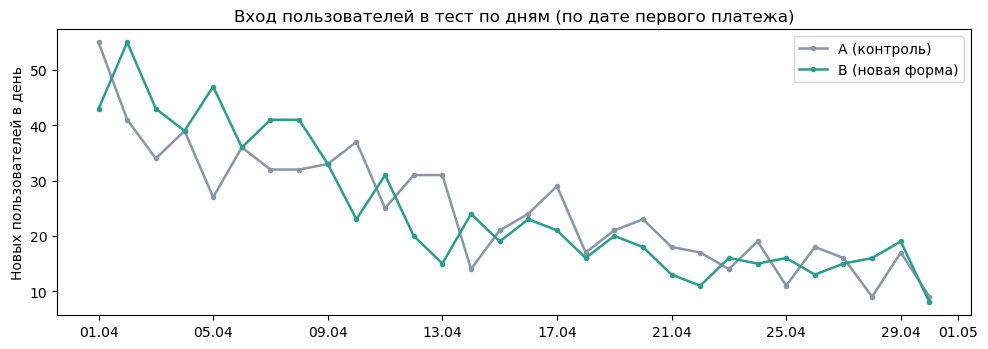

In [23]:
COL  = {"A": "#8896ab", "B": "#2a9d8f"}
NAME = {"A": "A (контроль)", "B": "B (новая форма)"}

fig, ax = plt.subplots(figsize=(10, 3.6))
for g_ in "AB":
    ax.plot(entry.index, entry[g_], marker="o", ms=3, lw=1.8, color=COL[g_], label=NAME[g_])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax.set_ylabel("Новых пользователей в день")
ax.set_title("Вход пользователей в тест по дням (по дате первого платежа)")
ax.legend()
plt.tight_layout()
ax.grid(False)
fig.savefig("figures/conversion1.png", dpi=200, bbox_inches="tight")
plt.show()

**Итог проверки**
- Группы одинакового размера (750 и 750) и сопоставимы по городу и возрасту.
- По устройству есть небольшой перекос (Android 54% в A и 49% в B, p = 0,06), он не значим на уровне 0,05.
- Вход в тест равномерен по дням.

# 5. Статистическая проверка гипотезы

### Выбор метода

- Конверсия это долевая и бинарная метрика (оплатил / не оплатил), группы независимы (сплит по клиентам), выборки достаточно большие (по 750 человек).
- Поэтому для основной метрики используем **z-тест для двух долей** с 95% доверительным интервалом разницы.
- Для проверки используем - критерий χ².
- Тест двусторонний (чтобы заметить и ухудшение), уровень значимости 0,05.

### Основной тест и ДИ

In [24]:
# z-тест для двух долей и доверительный интервал
def two_prop(x1, n1, x2, n2):
    """z-тест для двух долей. Возвращает доли, разницу, 95% ДИ разницы и p-value."""
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    z = (p2 - p1) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    diff = p2 - p1
    return p1, p2, diff, (diff - 1.96 * se, diff + 1.96 * se), 2 * stats.norm.sf(abs(z))

x = df.groupby("group").f4.agg(["sum", "count"])
pA, pB, diff, ci, p = two_prop(x.loc["A", "sum"], x.loc["A", "count"], x.loc["B", "sum"], x.loc["B", "count"])

print(f"Конверсия 1→4:  A = {pA*100:.1f}%   B = {pB*100:.1f}%")
print(f"Разница: {diff*100:+.1f} п.п., 95% ДИ [{ci[0]*100:.1f}; {ci[1]*100:.1f}]")
print(f"Относительный прирост: {diff/pA*100:+.1f}%")
print(f"z-тест: p = {p:.1e}")

Конверсия 1→4:  A = 65.5%   B = 80.4%
Разница: +14.9 п.п., 95% ДИ [10.5; 19.4]
Относительный прирост: +22.8%
z-тест: p = 7.6e-11


### Дополнительный тест

In [25]:
# Проверка критерием χ²
table = [[x.loc["A", "sum"], x.loc["A", "count"] - x.loc["A", "sum"]],
         [x.loc["B", "sum"], x.loc["B", "count"] - x.loc["B", "sum"]]]
print(f"Проверка критерием χ²: p = {stats.chi2_contingency(table, correction=False)[1]:.1e}")

Проверка критерием χ²: p = 7.6e-11


### Эффект по шагам воронки

In [26]:
g = df.groupby("group")[["f1", "f2", "f3", "f4"]].sum()
rows = []
for prev, nxt, name in [("f1", "f2", "1→2"), ("f2", "f3", "2→3"), ("f3", "f4", "3→4")]:
    pa, pb, d, _, p_ = two_prop(g.loc["A", nxt], g.loc["A", prev], g.loc["B", nxt], g.loc["B", prev])
    rows.append({"переход": name, "A, %": round(pa * 100, 1), "B, %": round(pb * 100, 1),
                 "разница, п.п.": round(d * 100, 1), "p": f"{p_:.1e}", "p (Бонферрони ×3)": f"{min(1, p_ * 3):.1e}"})
display(pd.DataFrame(rows))

,переход,"A, %","B, %","разница, п.п.",p,p (Бонферрони ×3)
0,1→2,89.3,94.3,4.9,5.0e-04,1.5e-03
1,2→3,81.5,91.1,9.6,2.0e-07,6.1e-07
2,3→4,89.9,93.6,3.7,1.9e-02,5.8e-02


Шагов три, поэтому p-value умножено на 3 (поправка Бонферрони на множественные сравнения).

### Эффект по сегментам

In [27]:
for col in ["device_type", "city"]:
    t = df.groupby([col, "group"]).f4.mean().unstack() * 100
    t["разница, п.п."] = t.B - t.A
    display(t.round(1))

group,A,B,"разница, п.п."
device_type,,,
android,64.3,79.9,15.7
ios,66.9,80.8,14.0


group,A,B,"разница, п.п."
city,,,
Москва,62.2,81.0,18.9
Регион,66.8,76.3,9.5
СПб,68.6,84.4,15.9


# 6. Визуализации

### 6.1 Воронка по группам

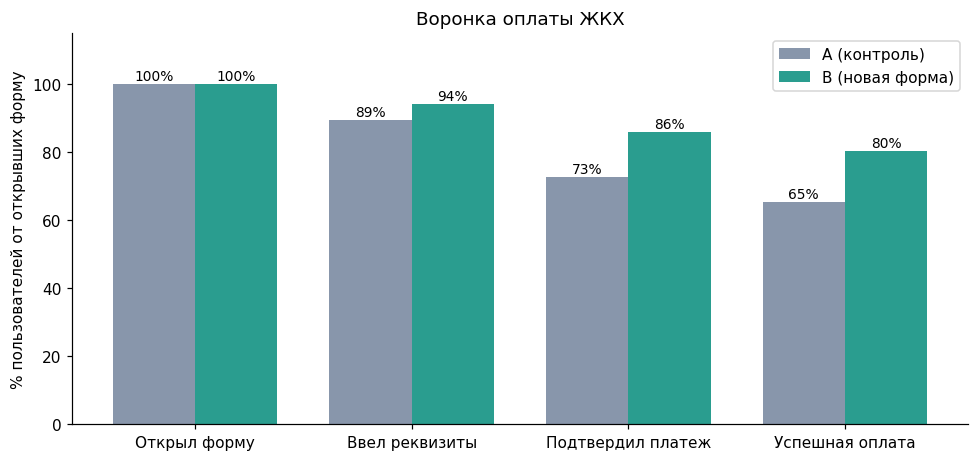

In [28]:
funnel = df.groupby("group")[["f1", "f2", "f3", "f4"]].sum()
share = funnel.div(funnel.f1, axis=0) * 100
labels = ["Открыл форму", "Ввел реквизиты", "Подтвердил платеж", "Успешная оплата"]

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

fig, ax = plt.subplots(figsize=(9, 4.3))
x_, w = np.arange(4), 0.38
for g_, off in [("A", -w / 2), ("B", w / 2)]:
    ax.bar(x_ + off, share.loc[g_].values, w, color=COL[g_], label=NAME[g_])
    for xi, v in zip(x_ + off, share.loc[g_].values):
        ax.text(xi, v + 1.2, f"{v:.0f}%", ha="center", fontsize=9)
ax.set_xticks(x_); ax.set_xticklabels(labels); ax.set_ylim(0, 115)
ax.set_ylabel("% пользователей от открывших форму"); ax.set_title("Воронка оплаты ЖКХ")
ax.legend(loc="upper right")
ax.grid(False)
plt.tight_layout()
fig.savefig("figures/conversion2.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.2 Конверсия 1→4 с доверительными интервалами

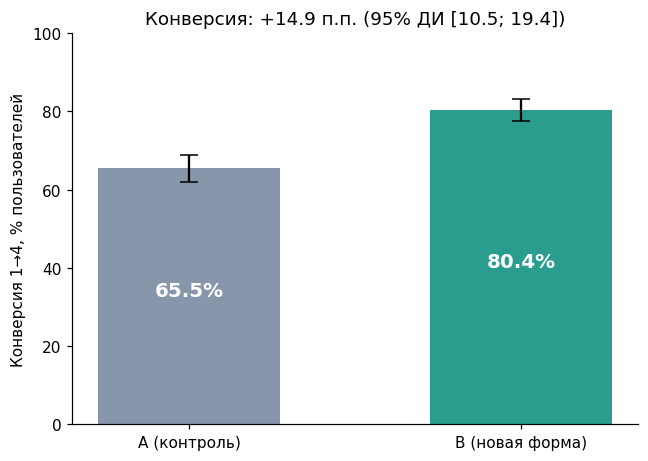

In [29]:
fig, ax = plt.subplots(figsize=(6, 4.3))
for i, g_ in enumerate("AB"):
    d = df[df.group == g_].f4; p_ = d.mean(); se = np.sqrt(p_ * (1 - p_) / len(d))
    ax.bar(i, p_ * 100, color=COL[g_], width=0.55, yerr=1.96 * se * 100, capsize=6)
    ax.text(i, p_ * 50, f"{p_*100:.1f}%", ha="center", color="white", fontsize=13, fontweight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels([NAME["A"], NAME["B"]]); ax.set_ylim(0, 100)
ax.set_ylabel("Конверсия 1→4, % пользователей")
ax.set_title(f"Конверсия: {diff*100:+.1f} п.п. (95% ДИ [{ci[0]*100:.1f}; {ci[1]*100:.1f}])")
ax.grid(False)
plt.tight_layout()
fig.savefig("figures/conversion3.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.3 Динамика конверсии по дням

Дней, когда конверсия B выше A: 29 из 30


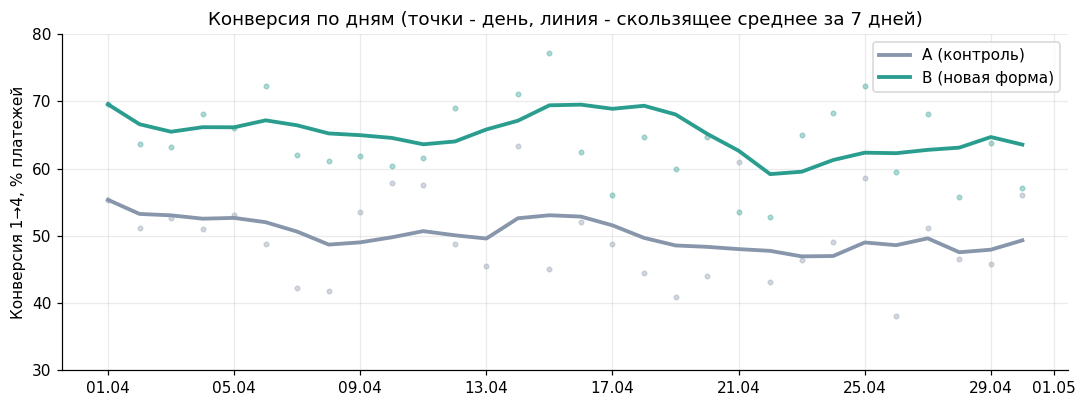

In [30]:
pay["day"] = pay.step1_opened.dt.normalize()
daily = pay.groupby(["day", "group"]).f4.mean().unstack() * 100
print("Дней, когда конверсия B выше A:", (daily.B > daily.A).sum(), "из", len(daily))

fig, ax = plt.subplots(figsize=(10, 3.8))
for g_ in "AB":
    ax.plot(daily.index, daily[g_], "o", ms=3, alpha=0.35, color=COL[g_])
    ax.plot(daily.index, daily[g_].rolling(7, min_periods=1).mean(), lw=2.5, color=COL[g_], label=NAME[g_])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax.set_ylabel("Конверсия 1→4, % платежей"); ax.set_ylim(30, 80)
ax.set_title("Конверсия по дням (точки - день, линия - скользящее среднее за 7 дней)")
ax.legend()
plt.tight_layout()
fig.savefig("figures/conversion4.png", dpi=200, bbox_inches="tight")
plt.show()

# 7. Выводы, ограничения и рекомендации

## Выводы
- **Нулевая гипотеза отвергается: новая форма оплаты с автозаполнением реквизитов статистически значимо повышает долю успешных оплат.** По результатам статистического теста значение p-value составило p = 8·10⁻¹¹, что кратно меньше установленного уровня значимости a = 0,05. 
- **Конверсия 1→4 выросла с 65,5% (A) до 80,4% (B)**: разница **+14,9 п.п.**. С 95% уверенностью истинный прирост лежит в доверительном интервале **[10,5; 19,4]**, весь интервал положительный и далек от нуля, значит эффект точно есть. Относительный прирост **+22,8%**. 
- **По шагам воронки** конверсия группы B лучше на всех переходах. Сильнее всего выросла конверсия шага подтверждения платежа (2→3, +9,6 п.п.), заметно выросла на вводе реквизитов (1→2, +4,9 п.п.). На этапе успешной оплаты выросла немного меньше (3→4, +3,7 п.п.) при p = 0,019: после поправки Бонферрони значение p-value находится на границе значимости (p = 0,058).
- **По сегментам** эффект положительный везде: Android +15,7 п.п., iOS +14,0 п.п.; Москва +18,9, СПб +15,9, регионы +9,5 п.п..
- **Динамика:** группа B выше группы A почти каждый день теста, эффект со временем не затухает.
- **Качество теста:** группы одинакового размера и сопоставимы по городу и возрасту, из данных удалено 8 некорректных записей.

## Ограничения и нюансы
- **Отсутствие защитных метрик.** В данных нет сумм платежей, возвратов, ошибок и обращений в поддержку. Автозаполнение могло привести к ухудшению одной из этих метрик, этого мы по данным проверить не можем.
- **Сезонность платежей ЖКХ не проверена.** Тест длился один месяц (апрель).
- **Гипотеза объясняет рост на шаге ввода реквизитов**, но не объясняет рост на шагах подтверждения и оплаты. Стоит уточнить у команды, что еще менялось в новой форме.
- **У пользователя бывает до 4 платежей**: метрика считалась на уровне пользователя (оплатил хотя бы раз), как и требует сплит по клиентам.

## Рекомендации
- **Раскатить новую форму на всех пользователей, но постепенно:** сначала на 25–50% аудитории, затем на 100% с мониторингом конверсии.
- **Ввести защитные метрики**: доля возвратов и отмен, число ошибочных платежей, обращений в поддержку, повторных платежей.
- **На первые 2–4 недели оставить небольшой контрольный срез (5–10%) на старой форме**, чтобы подтвердить эффект на более длинном горизонте и в другом платежном цикле.
- **Выяснить у команды разработки, какие еще изменения вошли в новую форму**, чтобы понимать, что еще могло дать эффект.